In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,  OneHotEncoder
from sklearn.metrics import r2_score, mean_squared_error

print("All libraries imported successfully")

All libraries imported successfully


In [2]:
housing = fetch_openml(
    name="house_prices",
    version=1,
    as_frame=True
)
df= housing.frame.copy()
print("Dataset loaded")
print("Datasetshape : ", df.shape)

Dataset loaded
Datasetshape :  (1460, 81)


In [3]:
display(df.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [5]:
with pd.option_context('display.max_rows', None):
    print(df.isnull().sum())

Id                  0
MSSubClass          0
MSZoning            0
LotFrontage       259
LotArea             0
Street              0
Alley            1369
LotShape            0
LandContour         0
Utilities           0
LotConfig           0
LandSlope           0
Neighborhood        0
Condition1          0
Condition2          0
BldgType            0
HouseStyle          0
OverallQual         0
OverallCond         0
YearBuilt           0
YearRemodAdd        0
RoofStyle           0
RoofMatl            0
Exterior1st         0
Exterior2nd         0
MasVnrType          8
MasVnrArea          8
ExterQual           0
ExterCond           0
Foundation          0
BsmtQual           37
BsmtCond           37
BsmtExposure       38
BsmtFinType1       37
BsmtFinSF1          0
BsmtFinType2       38
BsmtFinSF2          0
BsmtUnfSF           0
TotalBsmtSF         0
Heating             0
HeatingQC           0
CentralAir          0
Electrical          1
1stFlrSF            0
2ndFlrSF            0
LowQualFin

In [6]:
# Create a summary table showing missing count and data type
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Data_Type': df.dtypes
})

# Display only columns that have missing values
print(missing_summary[missing_summary['Missing_Count'] > 0])

              Missing_Count Data_Type
LotFrontage             259   float64
Alley                  1369    object
MasVnrType                8    object
MasVnrArea                8   float64
BsmtQual                 37    object
BsmtCond                 37    object
BsmtExposure             38    object
BsmtFinType1             37    object
BsmtFinType2             38    object
Electrical                1    object
FireplaceQu             690    object
GarageType               81    object
GarageYrBlt              81   float64
GarageFinish             81    object
GarageQual               81    object
GarageCond               81    object
PoolQC                 1453    object
Fence                  1179    object
MiscFeature            1406    object


In [7]:
X= df.drop(columns=["SalePrice", "Id"],errors="ignore")
y=pd.to_numeric(df["SalePrice"])

print("Features shape:" , X.shape)
print("Target shape: ", y.shape)

print("\nTarget variable:")
print(y.head())

print("\nMissing values: ")
print(X.isnull().sum().sum())

Features shape: (1460, 79)
Target shape:  (1460,)

Target variable:
0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

Missing values: 
6965


In [8]:
print(df.select_dtypes(include=['float64', 'int64']).describe())

                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1460.000000  1460.000000  1201.000000    1460.000000  1460.000000   
mean    730.500000    56.897260    70.049958   10516.828082     6.099315   
std     421.610009    42.300571    24.284752    9981.264932     1.382997   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     365.750000    20.000000    59.000000    7553.500000     5.000000   
50%     730.500000    50.000000    69.000000    9478.500000     6.000000   
75%    1095.250000    70.000000    80.000000   11601.500000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  ...  \
count  1460.000000  1460.000000   1460.000000  1452.000000  1460.000000  ...   
mean      5.575342  1971.267808   1984.865753   103.685262   443.639726  ...   
std       1.112799    30.202904     20.645407   181.066207   456.098091  ..

In [9]:
X_train, X_test , y_train, y_test = train_test_split(
    X,y,test_size=0.2, random_state=42
)

In [10]:
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
cat_cols= X_train.select_dtypes(include=['object']).columns

num_pipeline= Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scalar', StandardScaler())
])

cat_pipeline=Pipeline([
    ('imputer' , SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [11]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)


Processed X_train shape: (1168, 302)
Processed X_test shape: (292, 302)


In [12]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha= 10.0)
ridge.fit(X_train_processed, y_train)

print("Ridge model trained successfully!")

Ridge model trained successfully!


In [13]:
y_pred =  ridge.predict(X_test_processed)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score: {r2:.4f}")
print(f"RMSE: ${rmse:,.2f}")

R² Score: 0.8785
RMSE: $30,529.61


In [14]:
from sklearn.linear_model import RidgeCV

ridge_cv = RidgeCV(alphas=[0.1, 1.0, 5.0, 10.0, 15.0, 20.0, 50.0, 100.0])
ridge_cv.fit(X_train_processed, y_train)

print(f"Best alpha: {ridge_cv.alpha_}")
print(f"Tuned R² Score: {r2_score(y_test, ridge_cv.predict(X_test_processed)):.4f}")

Best alpha: 20.0
Tuned R² Score: 0.8759


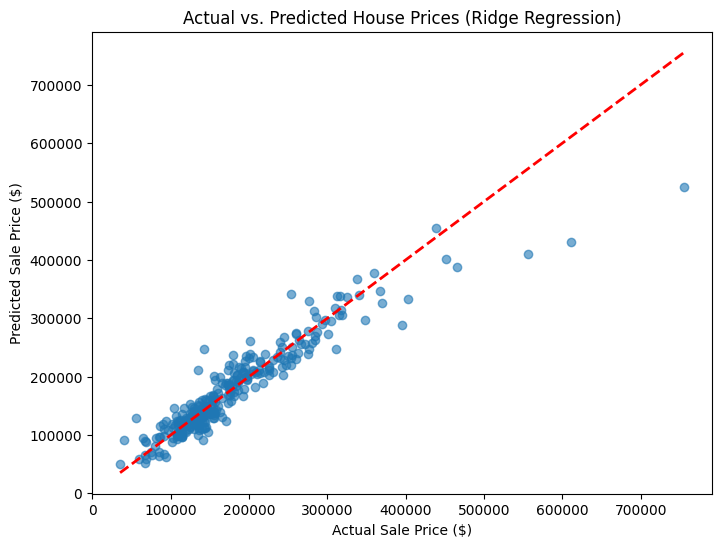

In [15]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title("Actual vs. Predicted House Prices (Ridge Regression)")
plt.show()

In [16]:
from sklearn.linear_model import LinearRegression

# Train standard Linear Regression
lr = LinearRegression()
lr.fit(X_train_processed, y_train)

# Compare test scores
lr_r2 = r2_score(y_test, lr.predict(X_test_processed))
ridge_r2 = r2_score(y_test, ridge.predict(X_test_processed))

print(f"Linear Regression R² : {lr_r2:.4f}")
print(f"Ridge Regression R²  : {ridge_r2:.4f}")


Linear Regression R² : 0.4435
Ridge Regression R²  : 0.8785
